In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt



In [2]:
# Load the CSV file
file_path = 'data/gold_cad.csv'
gold_data = pd.read_csv(file_path)

In [3]:
gold_data.head(10)

,Date,Close
0,1/2/2001,400.90
1,1/3/2001,401.68
2,1/4/2001,400.51
3,1/5/2001,401.92
4,1/8/2001,400.42
5,1/9/2001,399.73
6,1/10/2001,395.55
7,1/11/2001,394.50
8,1/12/2001,395.89
9,1/16/2001,396.72


In [4]:
#1: Generate synthetic sentiment data
np.random.seed(42)  # For reproducibility
gold_data['Sentiment'] = np.random.uniform(-1, 1, size=len(gold_data))

In [5]:
#2: Create lag features
gold_data['Previous_Close'] = gold_data['Close'].shift(1)

In [6]:
#3: Create the target variable (1 if price increased, 0 if decreased or stayed the same)
gold_data['Price_Up'] = (gold_data['Close'] > gold_data['Previous_Close']).astype(int)

In [7]:
# Drop any rows with NaN values generated due to lagging
gold_data = gold_data.dropna()

In [8]:
#4: Prepare features and target variable
X = gold_data[['Sentiment', 'Previous_Close']]
y = gold_data['Price_Up']

In [9]:
# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# Step 5: Train a logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [11]:
# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [12]:
# Step 6: Evaluate the model using a confusion matrix and ROC curve
conf_matrix = confusion_matrix(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
fpr, tpr, _ = roc_curve(y_test, y_prob)

In [23]:
from sklearn.metrics import accuracy_score

y_rnn_pred_binary = np.round(y_pred)

print("VADER Accuracy: %.2f" % (accuracy_score(y_test , y_pred)))

VADER Accuracy: 0.49


**The Accuracy is Poor**

In [14]:
# Print the AUC score
print("ROC AUC Score:", roc_auc)

ROC AUC Score: 0.4691885519147898


In [17]:
#Classification Report
from sklearn.metrics import classification_report

#Classification Report for VADER
print("Classification Report for VADER")
print(classification_report(y_pred , y_test))

Classification Report for VADER
              precision    recall  f1-score   support

           0       0.20      0.46      0.28       214
           1       0.77      0.50      0.60       778

    accuracy                           0.49       992
   macro avg       0.48      0.48      0.44       992
weighted avg       0.65      0.49      0.53       992



In [19]:
#Confusion Matrix For VADER
tn_vader , fp_vader , fn_vader , tp_vader = confusion_matrix(y_test , y_pred).ravel()

#Dataframe ro display confusion matrix from vader

cm_vader_df = pd.DataFrame(
    {
        "Positive(1)":[f"TP={tp_vader}" , f"FP={fp_vader}"],
        "Negative(0)":[f"FN={fn_vader}" , f"TN={tn_vader}"],
    },
    index=["Positive(1)" , "Negative(0)"],
)
cm_vader_df.index.name = "Actual"
cm_vader_df.columns.name = "Predicted"
print("Confusion Matrix From VADER")
display(cm_vader_df)

Confusion Matrix From VADER


Predicted,Positive(1),Negative(0)
Actual,,
Positive(1),TP=386,FN=116
Negative(0),FP=392,TN=98


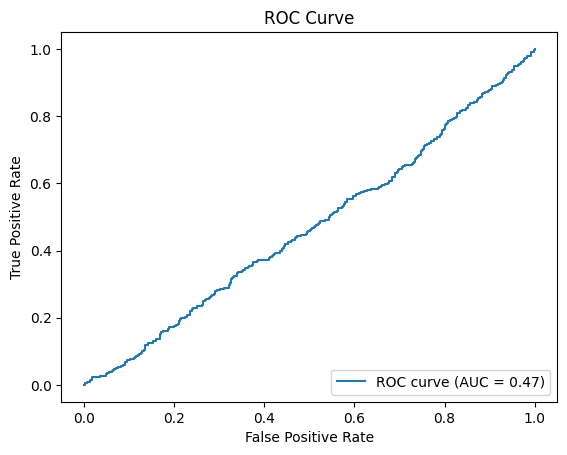

In [25]:
# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()

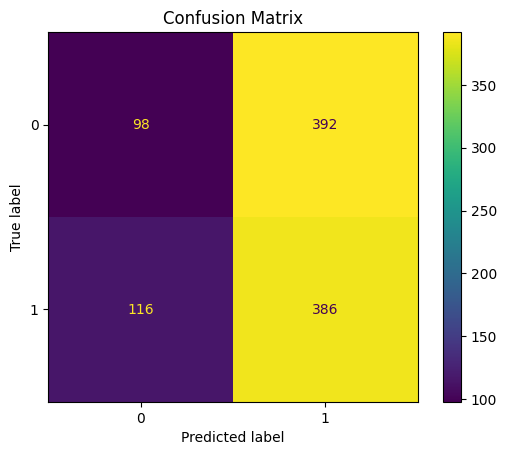

In [24]:
# Plot confusion matrix
ConfusionMatrixDisplay(conf_matrix).plot()
plt.title('Confusion Matrix')
plt.show()